# Iteration 2: Multimodal Fusion

This notebook adds forward-scene video to the temporal tabular model.
It uses:

- the same 4-class impairment task
- the same fixed participant folds
- tabular gaze and vehicle/control windows
- sampled front-camera frames
- a lightweight scene encoder plus simple cross-modal attention

The notebook also supports modality-drop ablations:
- `tabular_only`
- `video_only`
- `fusion`

In [1]:
from pathlib import Path

def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "dataset" / "README.md").exists():
            return candidate
    raise FileNotFoundError("Could not find the project root containing dataset/README.md.")

root = find_project_root(Path.cwd().resolve())
dbm_repo = root / "dataset"
data_dir = root / "data" / "IDD"

version = "only-scaled-rgb-video"

target_fps = 10
chunk_duration_s = 30.0
chunks_per_scenario = 1
rebuild_window_cache = False
progress_every = 10

num_video_frames = 8
image_size = 96

artifact_dir = root / "artifacts" / "multimodal_fusion"
artifact_dir.mkdir(parents=True, exist_ok=True)
cache_dir = artifact_dir / "window_cache"

# Full Iteration 2 run: all fixed folds and all modality ablations.
run_all_folds = True
experiment_modes = ["tabular_only", "video_only", "fusion"]

seed = 42
batch_size = 4
epochs = 25
patience = 8
learning_rate = 3e-4
# Iteration 2 tuning (see artifacts/multimodal_fusion/sweep_tabular_only*.csv): a small
# regularization bump over the original run. Unlike notebook 03, removing the weighted
# sampler here did *not* help (0.317 vs 0.337 UAR on a matched sweep) -- this
# architecture's imbalance sensitivity differs from the unimodal transformer, so we kept
# focal loss + the sampler and only raised dropout/weight_decay. Net effect was small and
# mode-dependent: tabular_only ticked up (0.355 -> 0.358), fusion ticked down slightly
# (0.369 -> 0.349), video_only improved the most (0.190 -> 0.258). All of these deltas are
# well within the bootstrap CI width reported in artifacts/ensemble/bootstrap_ci.csv --
# i.e. mostly noise, not a real fix. The honest conclusion is that this architecture is
# capacity- and data-limited (only ~250-300 training clips for the video branch) in a way
# hyperparameter tuning alone doesn't resolve; see the README for what that implies.
weight_decay = 1e-3
normalize_inputs = True

model_dim = 128
num_heads = 4
tabular_num_layers = 2
video_num_layers = 2
ff_dim = 256
dropout = 0.3

# The from-scratch CNN (LightweightSceneEncoder) has only ~250-300 training clips to
# learn visual features from, which is why video_only scores near chance (see
# artifacts/multimodal_fusion/all_folds/video_only/overall_metrics.csv).
# Starting from ImageNet features needs far less data for a usable representation.
video_backbone = "resnet18"  # "resnet18", "mobilenet_v3_small", or "scratch" for the old CNN
freeze_video_backbone = True

# Same class-imbalance handling as notebook 03's Iteration 1 attempt -- kept here
# because, unlike notebook 03, it was not clearly harmful for this architecture (see
# weight_decay comment above).
loss_type = "focal"  # "ce" or "focal"
focal_gamma = 2.0
use_weighted_sampler = True

root

WindowsPath('C:/projects/DriverStateNet')

In [2]:
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

for name in list(sys.modules):
    if name == "data" or name.startswith("data."):
        sys.modules.pop(name, None)
    if name == "hail_datasets" or name.startswith("hail_datasets."):
        sys.modules.pop(name, None)

import src.data_bootstrap as data_bootstrap
import src.multimodal_fusion as multimodal_fusion

importlib.reload(data_bootstrap)
importlib.reload(multimodal_fusion)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)
np.set_printoptions(suppress=True)

## 1. PyTorch Check

This notebook needs the working PyTorch environment used in notebook 03.

In [3]:
multimodal_fusion.require_torch()
torch = multimodal_fusion.torch
device = multimodal_fusion.choose_device(prefer_cuda=True)

print(f"Torch version: {torch.__version__}")
print(f"Device: {device}")

Torch version: 2.11.0+cu128
Device: cuda


## 2. Load the Video-Enabled Dataset and Build Multimodal Windows

In [4]:
processed_root = data_bootstrap.ensure_processed_dataset(
    dbm_repo=dbm_repo,
    processed_root=data_dir,
    version=version,
    download_if_missing=False,
    prompt_for_license=False,
)

manifest_path = root / "artifacts" / "bootstrap" / "scenario_manifest.csv"
if manifest_path.exists():
    manifest = pd.read_csv(manifest_path)
    print(f"Loaded manifest from {manifest_path}")
else:
    manifest = data_bootstrap.build_scenario_manifest(
        dbm_repo=dbm_repo,
        processed_root=processed_root,
        scenario_name_filter=r"driving/[0-9].*",
    )
    manifest_path = artifact_dir / "scenario_manifest.csv"
    manifest.to_csv(manifest_path, index=False)
    print(f"Built and saved manifest to {manifest_path}")

inspection_dataset = data_bootstrap.build_inspection_dataset(
    dbm_repo=dbm_repo,
    processed_root=processed_root,
    scenario_name_filter=r"driving/[0-9].*",
    chunk_strategy="end",
    chunk_duration_s=chunk_duration_s,
    chunks_per_scenario=chunks_per_scenario,
    chunk_end_offset_s=0.0,
    include_video=True,
)

print(f"Dataset length: {len(inspection_dataset)}")

Loaded manifest from C:\projects\DriverStateNet\artifacts\bootstrap\scenario_manifest.csv


chunk_fps not specified - using max feature frame rate of 60.


Constructed dataset contains 52 participants, 371 scenarios, and 371 chunks.
Dataset length: 371


In [5]:
cache_exists = (cache_dir / "multimodal_cache.npz").exists()
should_rebuild_cache = rebuild_window_cache or not cache_exists

if cache_exists and not should_rebuild_cache:
    multimodal_cache = multimodal_fusion.load_multimodal_window_cache(cache_dir)
    cache_mismatch = (
        int(multimodal_cache["target_fps"]) != int(target_fps)
        or int(multimodal_cache["num_video_frames"]) != int(num_video_frames)
        or int(multimodal_cache["image_size"]) != int(image_size)
    )
    if cache_mismatch:
        print("Cached multimodal windows do not match the requested settings. Rebuilding cache.")
        should_rebuild_cache = True
    else:
        print(f"Loaded cached multimodal windows from {cache_dir}")

if should_rebuild_cache:
    multimodal_cache = multimodal_fusion.build_multimodal_window_cache(
        inspection_dataset,
        manifest=manifest,
        target_fps=target_fps,
        num_video_frames=num_video_frames,
        image_size=image_size,
        progress_every=progress_every,
    )
    multimodal_fusion.save_multimodal_window_cache(multimodal_cache, cache_dir)
    print(f"Saved multimodal windows to {cache_dir}")

display(multimodal_fusion.multimodal_cache_summary(multimodal_cache))

Loaded cached multimodal windows from C:\projects\DriverStateNet\artifacts\multimodal_fusion\window_cache


,num_samples,tabular_sequence_length,tabular_num_features,num_video_frames,image_size,num_participants,num_folds,target_fps
0,371,300,84,8,96,52,5,10


impairment_label,baseline,cognitive_distraction,alcohol_intoxication,combined
fixed_fold,,,,
0,35,32,8,7
1,28,29,7,8
2,25,29,8,8
3,27,28,8,8
4,33,29,6,8


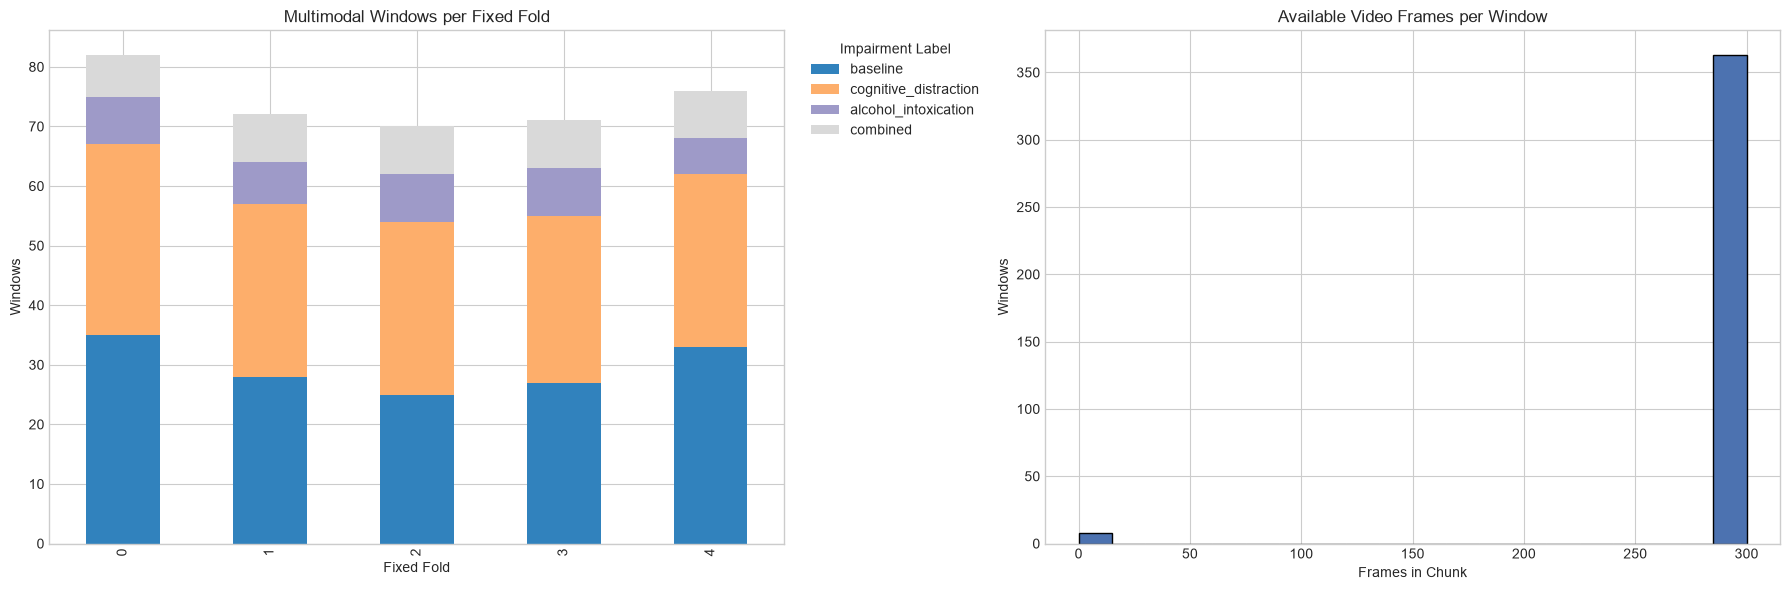

In [6]:
metadata = multimodal_cache["metadata"].copy()
fold_label_counts = pd.crosstab(
    metadata["fixed_fold"],
    metadata["impairment_label"],
).reindex(columns=data_bootstrap.LABEL_ORDER, fill_value=0)

display(fold_label_counts)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

fold_label_counts.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab20c")
axes[0].set_title("Multimodal Windows per Fixed Fold")
axes[0].set_xlabel("Fixed Fold")
axes[0].set_ylabel("Windows")
axes[0].legend(title="Impairment Label", bbox_to_anchor=(1.02, 1), loc="upper left")

frame_counts = metadata["num_video_frames_available"]
axes[1].hist(frame_counts, bins=20, color="#4C72B0", edgecolor="black")
axes[1].set_title("Available Video Frames per Window")
axes[1].set_xlabel("Frames in Chunk")
axes[1].set_ylabel("Windows")

fig.tight_layout()
fig.savefig(artifact_dir / "cache_overview.png", dpi=150, bbox_inches="tight")

In [7]:
print("Tabular tensor shape [N, T, F]:", multimodal_cache["tabular_x"].shape)
print("Video tensor shape [N, V, C, H, W]:", multimodal_cache["video_x"].shape)
print("Video valid-mask shape [N, V]:", multimodal_cache["video_valid_mask"].shape)
print("First 12 tabular feature names:")
display(pd.Series(multimodal_cache["feature_names"][:12], name="feature_name"))

Tabular tensor shape [N, T, F]: (371, 300, 84)
Video tensor shape [N, V, C, H, W]: (371, 8, 3, 96, 96)
Video valid-mask shape [N, V]: (371, 8)
First 12 tabular feature names:


0     ego_tracks__carla_objects_pose_x__delta_s
1        ego_tracks__carla_objects_pose_x__mask
2       ego_tracks__carla_objects_pose_x__value
3     ego_tracks__carla_objects_pose_y__delta_s
4        ego_tracks__carla_objects_pose_y__mask
5       ego_tracks__carla_objects_pose_y__value
6     ego_tracks__lateral_acceleration__delta_s
7        ego_tracks__lateral_acceleration__mask
8       ego_tracks__lateral_acceleration__value
9             ego_tracks__lateral_jerk__delta_s
10               ego_tracks__lateral_jerk__mask
11              ego_tracks__lateral_jerk__value
Name: feature_name, dtype: str

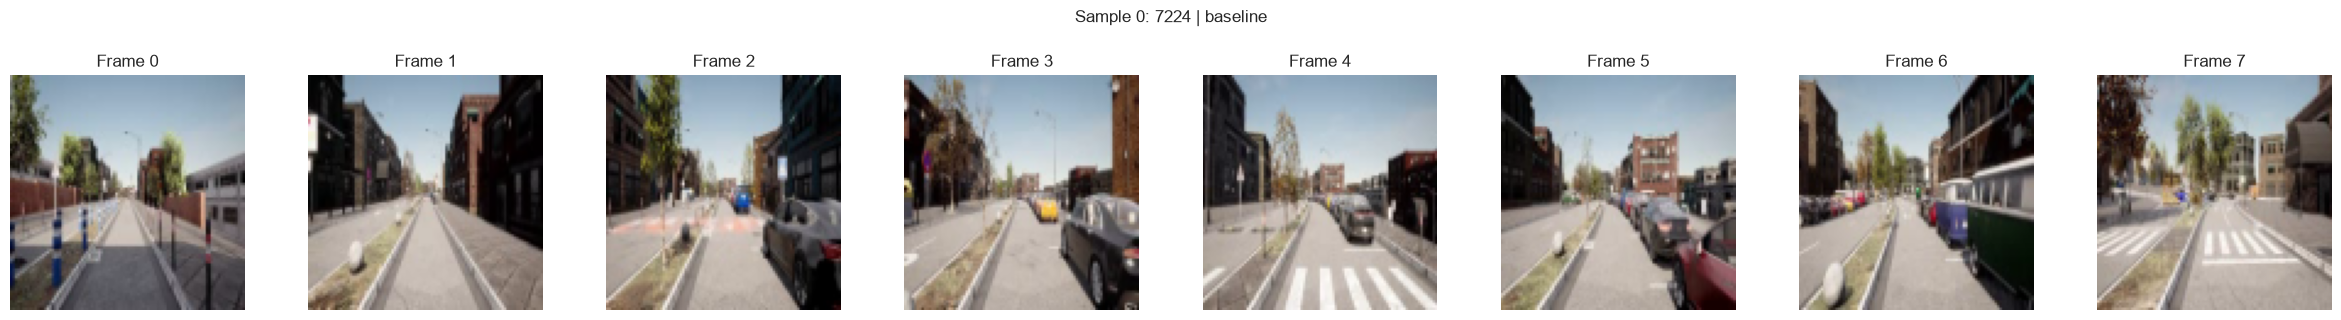

In [8]:
sample_idx = 0
sample_frames = multimodal_cache["video_x"][sample_idx]
sample_valid_mask = multimodal_cache["video_valid_mask"][sample_idx]
sample_meta = multimodal_cache["metadata"].iloc[sample_idx]

fig, axes = plt.subplots(1, len(sample_frames), figsize=(3 * len(sample_frames), 3))
if len(sample_frames) == 1:
    axes = [axes]
for frame_idx, ax in enumerate(axes):
    if sample_valid_mask[frame_idx]:
        frame = np.transpose(sample_frames[frame_idx], (1, 2, 0))
        ax.imshow(frame)
        ax.set_title(f"Frame {frame_idx}")
    else:
        ax.imshow(np.zeros((image_size, image_size, 3), dtype=np.uint8))
        ax.set_title(f"Frame {frame_idx}\nmissing")
    ax.axis("off")
fig.suptitle(
    f"Sample {sample_idx}: {sample_meta['participant_name']} | {sample_meta['impairment_label']}",
    y=1.05,
)
fig.tight_layout()

## 3. Train the Multimodal Model

Use `experiment_modes` for modality-drop ablations.

In [9]:
available_folds = sorted(metadata["fixed_fold"].astype(int).unique().tolist())
folds_to_run = available_folds if run_all_folds else [available_folds[0]]

print("Available folds:", available_folds)
print("Folds to run:", folds_to_run)
print("Experiment modes:", experiment_modes)

Available folds: [0, 1, 2, 3, 4]
Folds to run: [0, 1, 2, 3, 4]
Experiment modes: ['tabular_only', 'video_only', 'fusion']


In [10]:
multimodal_results = {}
fold_metrics_frames = []
per_class_frames = []

run_name = "all_folds" if run_all_folds else f"held_out_fold_{folds_to_run[0]}"
run_dir = artifact_dir / run_name
run_dir.mkdir(parents=True, exist_ok=True)

for mode in experiment_modes:
    print(f"\nRunning mode: {mode}")
    result = multimodal_fusion.run_fixed_fold_multimodal_experiment(
        cache=multimodal_cache,
        mode=mode,
        folds_to_run=folds_to_run,
        batch_size=batch_size,
        epochs=epochs,
        patience=patience,
        lr=learning_rate,
        weight_decay=weight_decay,
        model_dim=model_dim,
        num_heads=num_heads,
        tabular_num_layers=tabular_num_layers,
        video_num_layers=video_num_layers,
        ff_dim=ff_dim,
        dropout=dropout,
        normalize_inputs=normalize_inputs,
        loss_type=loss_type,
        focal_gamma=focal_gamma,
        use_weighted_sampler=use_weighted_sampler,
        video_backbone=video_backbone,
        freeze_video_backbone=freeze_video_backbone,
        device=device,
        seed=seed,
        label_names=data_bootstrap.LABEL_ORDER,
    )

    mode_dir = run_dir / mode
    mode_dir.mkdir(parents=True, exist_ok=True)

    result["fold_metrics"].to_csv(mode_dir / "fold_metrics.csv", index=False)
    result["predictions"].to_csv(mode_dir / "predictions.csv", index=False)
    result["history"].to_csv(mode_dir / "history.csv", index=False)
    result["overall_metrics"].to_csv(mode_dir / "overall_metrics.csv", header=["value"])
    result["overall_confusion"].to_csv(mode_dir / "overall_confusion.csv")
    result["per_class_report"].to_csv(mode_dir / "per_class_report.csv")

    multimodal_results[mode] = result
    fold_metrics_frames.append(result["fold_metrics"])
    per_class_frames.append(
        result["per_class_report"].reset_index().rename(columns={"index": "label"}).assign(model_name=mode)
    )

    display(result["fold_metrics"])
    display(result["overall_metrics"].to_frame("value"))
    display(result["per_class_report"])

overall_comparison = pd.DataFrame(
    [result["overall_metrics"].to_dict() for result in multimodal_results.values()]
).set_index("model_name")
fold_metrics = pd.concat(fold_metrics_frames, ignore_index=True)
per_class_report = pd.concat(per_class_frames, ignore_index=True)

overall_comparison.to_csv(run_dir / "model_comparison.csv")
fold_metrics.to_csv(run_dir / "fold_metrics_all_modes.csv", index=False)
per_class_report.to_csv(run_dir / "per_class_report_all_modes.csv", index=False)

display(overall_comparison)
display(fold_metrics)
display(per_class_report)


Running mode: tabular_only
Running tabular_only multimodal model for held-out fold 0


C:\projects\DriverStateNet\src\multimodal_fusion.py:502: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.tabular_encoder = nn.TransformerEncoder(tabular_encoder_layer, num_layers=tabular_num_layers)


Running tabular_only multimodal model for held-out fold 1


C:\projects\DriverStateNet\src\multimodal_fusion.py:502: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.tabular_encoder = nn.TransformerEncoder(tabular_encoder_layer, num_layers=tabular_num_layers)


Running tabular_only multimodal model for held-out fold 2


C:\projects\DriverStateNet\src\multimodal_fusion.py:502: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.tabular_encoder = nn.TransformerEncoder(tabular_encoder_layer, num_layers=tabular_num_layers)


... (32 outputs left out)

,precision,recall,f1,support
baseline,0.509615,0.358108,0.420635,148
cognitive_distraction,0.496241,0.448980,0.471429,147
alcohol_intoxication,0.216867,0.486486,0.300000,37
combined,0.078431,0.102564,0.088889,39


,uar,precision_macro,recall_macro,f1_macro,accuracy,num_samples,tabular_num_features,tabular_sequence_length,num_video_frames,image_size,num_folds,normalize_inputs,loss_type,use_weighted_sampler,video_backbone
model_name,,,,,,,,,,,,,,,
tabular_only,0.358091,0.338914,0.358091,0.320505,0.353100,371,84,300,8,96,5,True,focal,True,resnet18
video_only,0.257623,0.052457,0.257623,0.086934,0.105121,371,84,300,8,96,5,True,focal,True,resnet18
fusion,0.349035,0.325289,0.349035,0.320238,0.380054,371,84,300,8,96,5,True,focal,True,resnet18


,model_name,fixed_fold,validation_fold,num_train,num_val,num_test,best_epoch,normalize_inputs,loss_type,use_weighted_sampler,video_backbone,uar,precision_macro,recall_macro,f1_macro,accuracy
0,tabular_only,0,1,217,72,82,6,True,focal,True,resnet18,0.333482,0.294012,0.333482,0.203795,0.207317
1,tabular_only,1,2,229,70,72,7,True,focal,True,resnet18,0.460899,0.435000,0.460899,0.341029,0.347222
2,tabular_only,2,3,230,71,70,6,True,focal,True,resnet18,0.351207,0.334933,0.351207,0.333586,0.400000
3,tabular_only,3,4,224,76,71,10,True,focal,True,resnet18,0.265212,0.235431,0.265212,0.243939,0.408451
4,tabular_only,4,0,213,82,76,6,True,focal,True,resnet18,0.423034,0.385143,0.423034,0.363472,0.421053
5,video_only,0,1,217,72,82,7,True,focal,True,resnet18,0.187500,0.022388,0.187500,0.040000,0.073171
6,video_only,1,2,229,70,72,1,True,focal,True,resnet18,0.250000,0.027778,0.250000,0.050000,0.111111
7,video_only,2,3,230,71,70,1,True,focal,True,resnet18,0.250000,0.028571,0.250000,0.051282,0.114286
8,video_only,3,4,224,76,71,1,True,focal,True,resnet18,0.281250,0.153986,0.281250,0.101948,0.126761
9,video_only,4,0,213,82,76,1,True,focal,True,resnet18,0.250000,0.026316,0.250000,0.047619,0.105263


,label,precision,recall,f1,support,model_name
0,baseline,0.583333,0.425676,0.492188,148,tabular_only
1,cognitive_distraction,0.439560,0.272109,0.336134,147,tabular_only
2,alcohol_intoxication,0.181818,0.324324,0.233010,37,tabular_only
3,combined,0.150943,0.410256,0.220690,39,tabular_only
4,baseline,0.000000,0.000000,0.000000,148,video_only
5,cognitive_distraction,0.000000,0.000000,0.000000,147,video_only
6,alcohol_intoxication,0.106796,0.594595,0.181070,37,video_only
7,combined,0.103030,0.435897,0.166667,39,video_only
8,baseline,0.509615,0.358108,0.420635,148,fusion
9,cognitive_distraction,0.496241,0.448980,0.471429,147,fusion


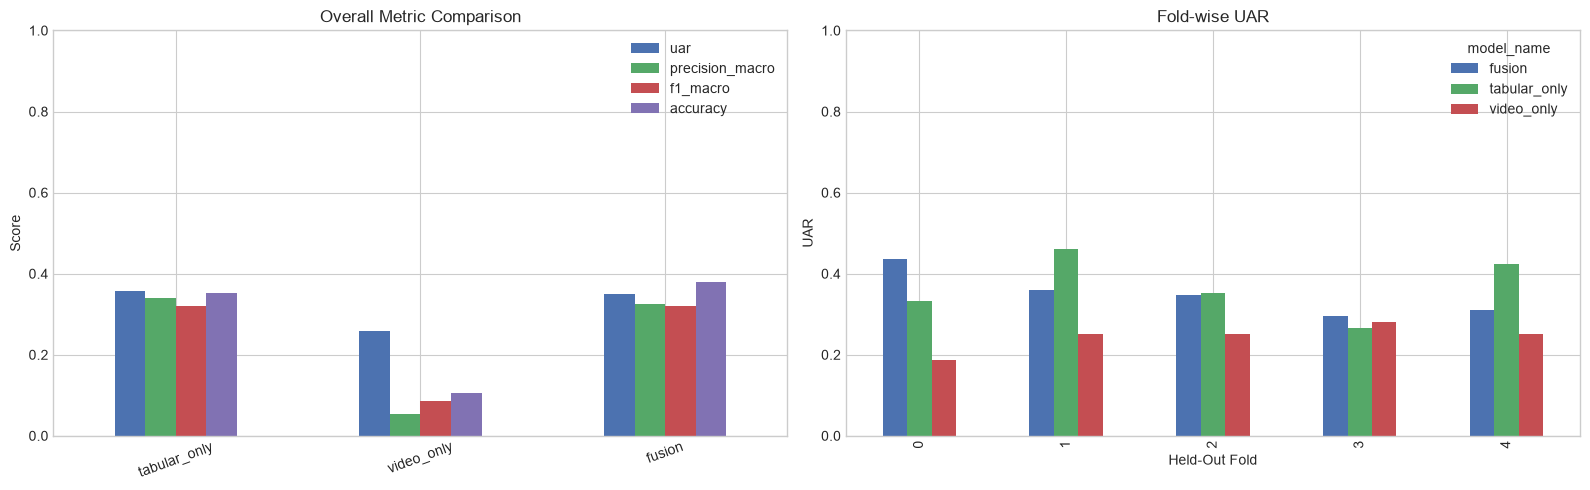

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

comparison_plot = overall_comparison[["uar", "precision_macro", "f1_macro", "accuracy"]]
comparison_plot.plot(kind="bar", ax=axes[0], color=["#4C72B0", "#55A868", "#C44E52", "#8172B3"])
axes[0].set_title("Overall Metric Comparison")
axes[0].set_xlabel("")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0.0, 1.0)
axes[0].tick_params(axis="x", rotation=20)

fold_pivot = fold_metrics.pivot(index="fixed_fold", columns="model_name", values="uar")
fold_pivot.plot(kind="bar", ax=axes[1], color=["#4C72B0", "#55A868", "#C44E52"][: len(fold_pivot.columns)])
axes[1].set_title("Fold-wise UAR")
axes[1].set_xlabel("Held-Out Fold")
axes[1].set_ylabel("UAR")
axes[1].set_ylim(0.0, 1.0)

fig.tight_layout()
fig.savefig(run_dir / "overall_metrics.png", dpi=150, bbox_inches="tight")

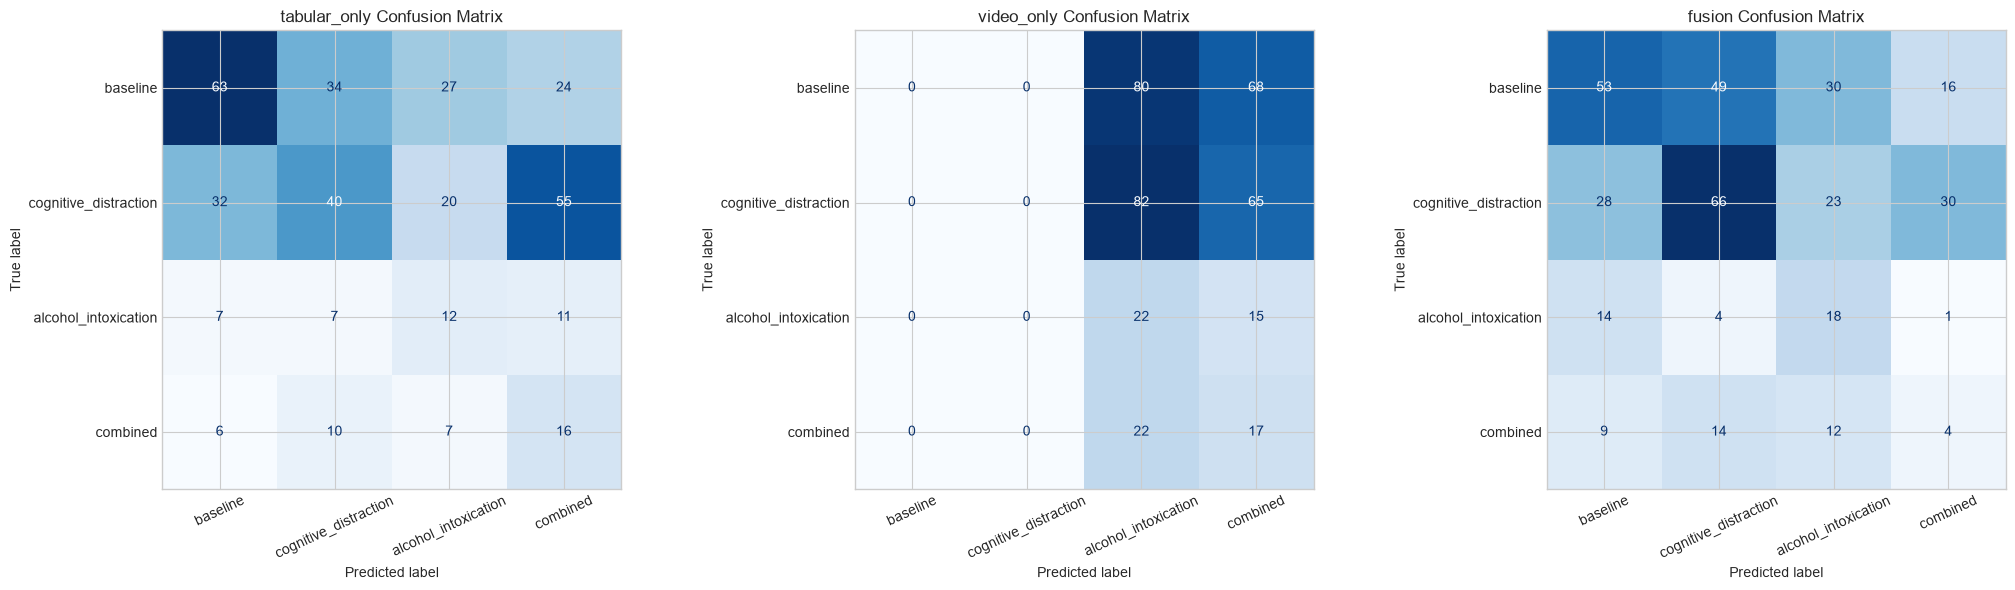

In [12]:
num_modes = len(multimodal_results)
fig, axes = plt.subplots(1, num_modes, figsize=(7 * num_modes, 6))
if num_modes == 1:
    axes = [axes]

for ax, mode in zip(axes, multimodal_results):
    result = multimodal_results[mode]
    confusion_display = ConfusionMatrixDisplay(
        confusion_matrix=result["overall_confusion"].to_numpy(),
        display_labels=result["overall_confusion"].index.to_list(),
    )
    confusion_display.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"{mode} Confusion Matrix")
    ax.tick_params(axis="x", rotation=25)

fig.tight_layout()
fig.savefig(run_dir / "confusion_matrices.png", dpi=150, bbox_inches="tight")

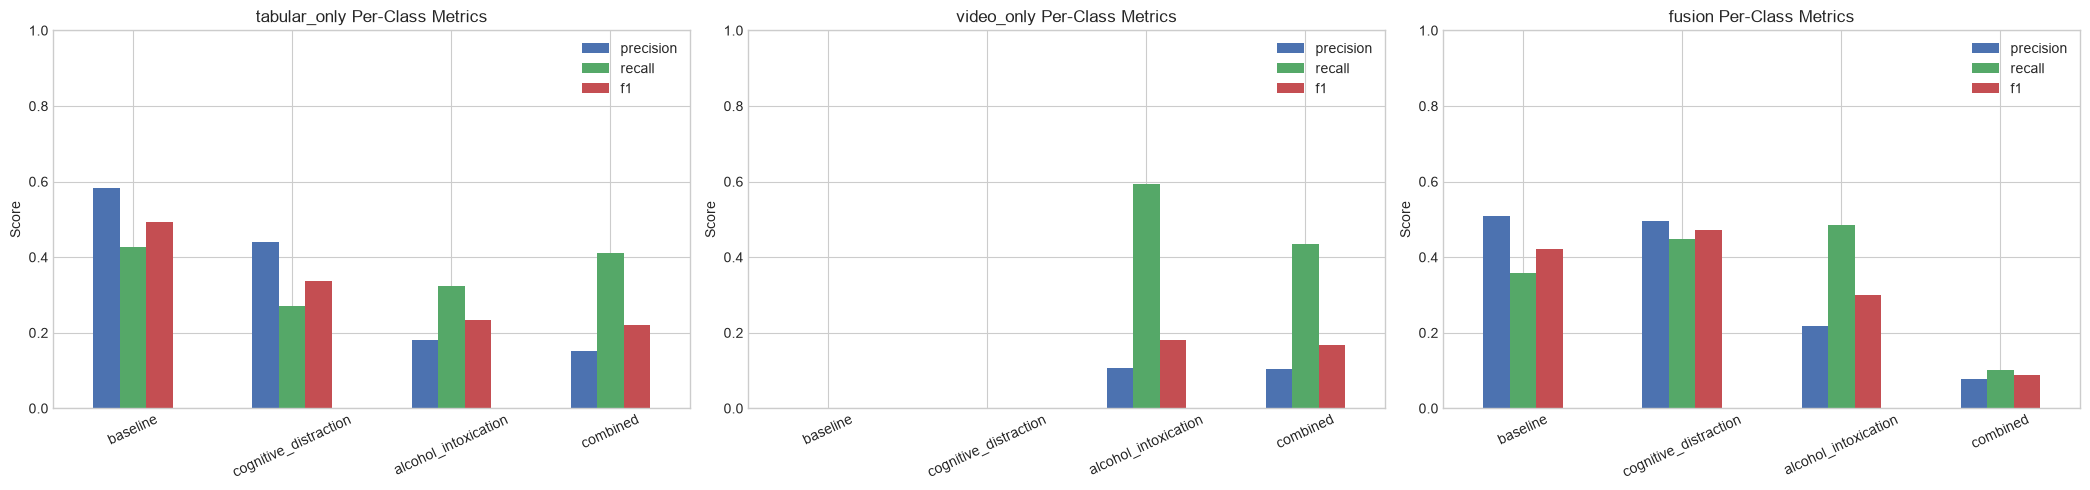

In [13]:
if len(multimodal_results) > 0:
    num_modes = len(multimodal_results)
    fig, axes = plt.subplots(1, num_modes, figsize=(7 * num_modes, 5))
    if num_modes == 1:
        axes = [axes]

    for ax, mode in zip(axes, multimodal_results):
        report = multimodal_results[mode]["per_class_report"].reset_index().rename(columns={"index": "label"})
        plot_df = report[["label", "precision", "recall", "f1"]].set_index("label")
        plot_df.plot(kind="bar", ax=ax, color=["#4C72B0", "#55A868", "#C44E52"])
        ax.set_title(f"{mode} Per-Class Metrics")
        ax.set_xlabel("")
        ax.set_ylabel("Score")
        ax.set_ylim(0.0, 1.0)
        ax.tick_params(axis="x", rotation=25)

    fig.tight_layout()
    fig.savefig(run_dir / "per_class_metrics.png", dpi=150, bbox_inches="tight")

## 4. Optional Comparison Against Earlier Notebooks

This comparison is most meaningful when all notebooks have been run with `run_all_folds = True`.

,uar,precision_macro,f1_macro,accuracy
model_name,,,,
logistic_regression,0.439852,0.421643,0.423321,0.498652
linear_svm,0.417289,0.413427,0.412842,0.517520
temporal_transformer,0.390666,0.386839,0.384406,0.458221
tabular_only,0.358091,0.338914,0.320505,0.353100
video_only,0.257623,0.052457,0.086934,0.105121
fusion,0.349035,0.325289,0.320238,0.380054


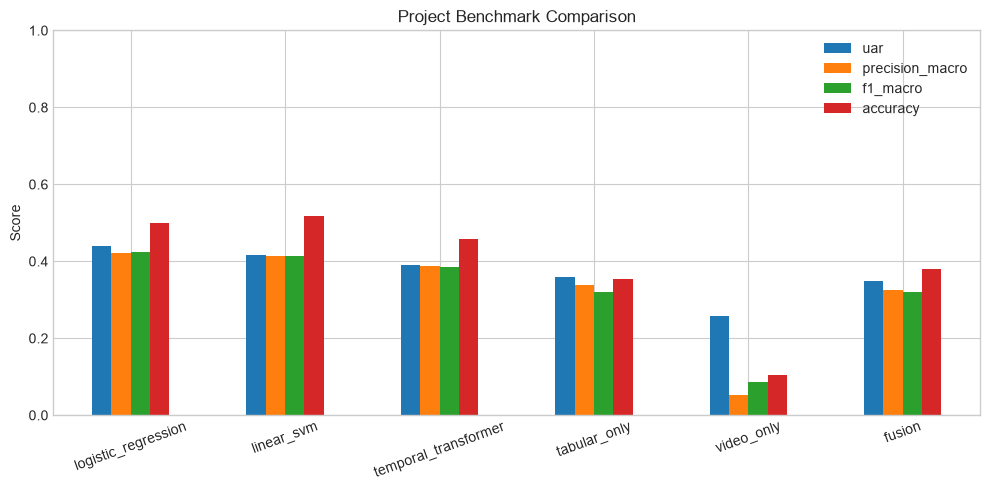

In [14]:
if run_all_folds:
    comparison_rows = []

    handcrafted_path = root / "artifacts" / "handcrafted_baseline" / "model_comparison.csv"
    if handcrafted_path.exists():
        handcrafted = pd.read_csv(handcrafted_path, index_col=0)
        handcrafted = handcrafted[["uar", "precision_macro", "f1_macro", "accuracy"]].apply(
            pd.to_numeric, errors="coerce"
        )
        comparison_rows.append(handcrafted)

    temporal_path = root / "artifacts" / "temporal_transformer" / "all_folds" / "overall_metrics.csv"
    if temporal_path.exists():
        temporal_metrics = pd.read_csv(temporal_path, index_col=0)["value"]
        temporal_row = pd.DataFrame([temporal_metrics.to_dict()]).set_index("model_name")
        temporal_row = temporal_row[["uar", "precision_macro", "f1_macro", "accuracy"]].apply(
            pd.to_numeric, errors="coerce"
        )
        comparison_rows.append(temporal_row)

    multimodal_comparison = overall_comparison[["uar", "precision_macro", "f1_macro", "accuracy"]].apply(
        pd.to_numeric, errors="coerce"
    )
    comparison_rows.append(multimodal_comparison)

    if comparison_rows:
        project_comparison = pd.concat(comparison_rows)
        display(project_comparison)

        ax = project_comparison.plot(kind="bar", figsize=(10, 5))
        ax.set_title("Project Benchmark Comparison")
        ax.set_xlabel("")
        ax.set_ylabel("Score")
        ax.set_ylim(0.0, 1.0)
        ax.tick_params(axis="x", rotation=20)
        plt.tight_layout()
        plt.savefig(run_dir / "project_comparison.png", dpi=150, bbox_inches="tight")
        plt.show()
else:
    print("Set run_all_folds = True if you want an all-fold comparison against notebooks 02b and 03.")